# Feature Reduction for Heart Disease Classification

**BTech data science project | Reproducible implementation**

Can 3, 5, or 7 original clinical inputs preserve useful performance relative to all 11?
This notebook shows the selection algorithm, trains reduced models, evaluates the
performance trade-off, and checks whether the same variables are selected consistently.
The companion notebook contains data cleaning and the paper-inspired CART baseline.

**Contents:** setup; evaluation protocol; complete selection implementation;
outer evaluation; performance comparisons; selection stability; compact demonstration;
findings, limitations, and references.

## 1. Setup and input data

Run from top to bottom after the baseline notebook, or use `scripts/run_all.py`.
The verified raw CSV and the baseline split assignments are reused. All original test
records remain outside feature selection.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown, Image
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/feature_selection.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.project import (FEATURES, TARGET, make_model_pipeline, load_dataset,
                         evaluate_pipeline, write_json, InvalidMeasurementCleaner)
from src.feature_selection import create_figures

BUDGETS = [3, 5, 7, 11]
TOLERANCE = 0.01
OUT = ROOT / 'output/feature_selection'
data, provenance = load_dataset(ROOT)
split = pd.read_csv(ROOT / 'data/processed/split_assignments.csv')
development_ids = split.loc[split['split'].eq('train'), 'source_row']
holdout_ids = split.loc[split['split'].eq('test'), 'source_row']
assert set(development_ids).isdisjoint(holdout_ids)
print('Development records:', len(development_ids), '| Excluded test records:', len(holdout_ids))
display(pd.read_csv(ROOT / 'data/processed/feature_dictionary.csv'))

Development records: 734 | Excluded test records: 184


,Feature,Type,Meaning / handling
0,Age,Numeric,Age in years
1,Sex,Categorical,"F or M, as recorded in the source"
2,ChestPainType,Categorical,TA=typical angina; ATA=atypical; NAP=non-angin...
3,RestingBP,Numeric,Resting blood pressure in mm Hg; zero treated ...
4,Cholesterol,Numeric,Serum cholesterol; zero treated as missing
5,FastingBS,Binary,1 if fasting blood sugar >120 mg/dL; otherwise 0
6,RestingECG,Categorical,"Normal, ST, or LVH"
7,MaxHR,Numeric,"Maximum heart rate achieved, beats per minute"
8,ExerciseAngina,Categorical,Exercise-induced angina: Y or N
9,Oldpeak,Numeric,Exercise-related ST depression; zero/negative ...


### Cleaning is unchanged from the baseline

Nonpositive cholesterol and resting blood pressure become missing. Numerical medians
and missingness indicators, categorical imputation and encoding, and LR scaling are
fitted inside every candidate's training fold. All encoded columns belonging to one
original variable stay together. Zero or negative Oldpeak and valid binary zeros remain.

In [2]:
development = data.loc[development_ids, FEATURES]
preview = InvalidMeasurementCleaner().fit_transform(development)
display(pd.DataFrame({'Raw empty cells': development.isna().sum(),
                      'After deterministic cleaning': preview.isna().sum()}))
assert len(preview) == len(development)

,Raw empty cells,After deterministic cleaning
Age,0,0
Sex,0,0
ChestPainType,0,0
RestingBP,0,0
Cholesterol,0,129
FastingBS,0,0
RestingECG,0,0
MaxHR,0,0
ExerciseAngina,0,0
Oldpeak,0,0


## 2. Evaluation protocol

1. Use only the original 734 development records; exclude the original 184 test records.
2. Use five stratified outer folds to evaluate the full selection procedure.
3. Inside each outer training partition, use three-fold CV and LR F1 to select variables.
4. Compare 3, 5, 7, and all 11 inputs on the same outer validation patients.
5. Use fixed LR settings (`C=1`) and a fixed RF comparison. RF uses the LR-selected subsets.
6. Choose the smallest budget within 0.01 absolute inner F1 of the all-11 inner F1.
   If none qualifies, retain all 11. Outer results do not choose the budget.

The tolerance is a design choice, not a significance or equivalence test. Inner search
scores can be optimistic; outer results evaluate the whole selection procedure.
Because earlier project exploration informed the design, these are development estimates.

## 3. Complete selection implementation

The following functions are generated from `src/feature_selection.py` so the notebook
and reusable implementation stay consistent. The shared pipeline is defined in full
in the baseline notebook and `src/project.py`. Charts use the shared plotting helper.

### Fixed models and the training-only budget rule

In [3]:
def model_for(features, family="LR"):
    estimator = (
        LogisticRegression(C=1.0, max_iter=2000, random_state=42)
        if family == "LR"
        else RandomForestClassifier(
            n_estimators=150, max_depth=8, min_samples_leaf=2, random_state=42, n_jobs=1
        )
    )
    return make_model_pipeline(
        estimator, scale_numeric=family == "LR", features=list(features)
    )

In [4]:
def choose_budget(scores, tolerance=TOLERANCE):
    """Smallest predefined subset within 0.01 absolute inner F1 of all 11."""
    return min(k for k in sorted(scores) if scores[k] >= scores[11] - tolerance - 1e-12)

### Greedy forward selection

Start with no variables. At each step, score each remaining original variable when
added to the current subset and keep the best candidate. Fixed feature order breaks ties.
Record every candidate score. Greedy search is not exhaustive and may miss interactions.

In [5]:
def forward_path(X, y, cv, max_features=7):
    selected = []
    candidates = []
    subsets = {}
    scores = {}
    for step in range(1, max_features + 1):
        step_scores = []
        for feature in FEATURES:
            if feature in selected:
                continue
            subset = selected + [feature]
            values = cross_val_score(
                model_for(subset),
                X[subset],
                y,
                cv=cv,
                scoring="f1",
                n_jobs=1,
                error_score="raise",
            )
            score = float(values.mean())
            step_scores.append((feature, score))
            candidates.append(
                {
                    "step": step,
                    "added_feature": feature,
                    "subset": json.dumps(subset),
                    "inner_f1": score,
                    "inner_f1_sd": float(values.std()),
                }
            )
        winner = max(step_scores, key=lambda item: item[1])[
            0
        ]  # fixed FEATURES order resolves ties
        selected.append(winner)
        if step in BUDGETS:
            subsets[step] = selected.copy()
            scores[step] = dict(step_scores)[winner]
    subsets[11] = FEATURES.copy()
    scores[11] = float(
        cross_val_score(
            model_for(FEATURES),
            X,
            y,
            cv=cv,
            scoring="f1",
            n_jobs=1,
            error_score="raise",
        ).mean()
    )
    return subsets, scores, candidates

### Outer evaluation and final demonstration fit

For each outer fold, selection and all preprocessing use only its training partition.
Each patient is evaluated once per model family and feature budget. After the outer
evaluation, the same selection rule fits a demonstration model on all development data.
That last fit does not replace the outer results or create a new independent test score.

In [6]:
def run_study(root):
    out = root / "output/feature_selection"
    for folder in ["tables", "models", "figures"]:
        (out / folder).mkdir(parents=True, exist_ok=True)
    protocol = {
        "date": "2026-11-15",
        "outer_folds": 5,
        "inner_folds": 3,
        "seed": 42,
        "budgets": BUDGETS,
        "selection_model": "LR C=1",
        "score": "F1",
        "compact_rule": "smallest budget within 0.01 absolute inner F1 of all 11",
        "scope": "734 original development records; original holdout excluded",
        "secondary_model": "fixed RF on LR-selected subsets, not separately RF-optimized",
    }
    write_json(out / "protocol.json", protocol)
    frame, prov = load_dataset(root)
    split = pd.read_csv(root / "data/processed/split_assignments.csv")
    ids = split.loc[split.split.eq("train"), "source_row"].to_numpy()
    X, y = frame.loc[ids, FEATURES], frame.loc[ids, TARGET]
    rows = []
    predictions = []
    choices = []
    candidates = []
    lineage = []
    for fold, (train, valid) in enumerate(
        StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)
    ):
        train_ids = X.index[train]
        valid_ids = X.index[valid]
        inner = StratifiedKFold(3, shuffle=True, random_state=500 + fold)
        subsets, scores, logs = forward_path(X.loc[train_ids], y.loc[train_ids], inner)
        compact = choose_budget(scores)
        candidates.extend({"fold": fold, **r} for r in logs)
        for role, source_ids in [("train", train_ids), ("validation", valid_ids)]:
            lineage.extend(
                {"fold": fold, "source_row": int(i), "role": role} for i in source_ids
            )
        for k, subset in subsets.items():
            choices.append(
                {
                    "fold": fold,
                    "budget": k,
                    "features": json.dumps(subset),
                    "inner_f1": scores[k],
                    "chosen_compact": k == compact,
                }
            )
            for family in ["LR", "RF"]:
                pipeline = model_for(subset, family).fit(
                    X.loc[train_ids, subset], y.loc[train_ids]
                )
                metrics, pred, p = evaluate_pipeline(
                    pipeline, X.loc[valid_ids, subset], y.loc[valid_ids]
                )
                rows.append(
                    {
                        "fold": fold,
                        "budget": k,
                        "family": family,
                        "chosen_compact": k == compact,
                        **metrics,
                    }
                )
                predictions.extend(
                    {
                        "fold": fold,
                        "budget": k,
                        "family": family,
                        "source_row": int(i),
                        "actual": int(actual),
                        "predicted": int(predicted),
                        "probability": float(probability),
                    }
                    for i, actual, predicted, probability in zip(
                        valid_ids, y.loc[valid_ids], pred, p
                    )
                )
                joblib.dump(
                    {
                        "model": pipeline,
                        "features": subset,
                        "train_ids": list(map(int, train_ids)),
                    },
                    out / f"models/fold_{fold}_{family}_{k}.joblib",
                    compress=3,
                )
        print(
            f"Outer fold {fold+1}/5: inner-selected compact budget {compact}; subset {subsets[compact]}",
            flush=True,
        )
    metrics = pd.DataFrame(rows)
    selection = pd.DataFrame(choices)
    summary = metrics.groupby(["family", "budget"])[
        ["accuracy", "f1", "recall", "specificity", "roc_auc"]
    ].agg(["mean", "std"])
    summary.columns = ["_".join(c) for c in summary.columns]
    summary = summary.reset_index()
    adaptive = (
        metrics.loc[metrics.chosen_compact]
        .groupby("family")[["accuracy", "f1", "recall", "specificity"]]
        .agg(["mean", "std"])
    )
    adaptive.columns = ["_".join(c) for c in adaptive.columns]
    adaptive = adaptive.reset_index()
    frequencies = []
    stability = []
    for k in [3, 5, 7]:
        sets = [
            set(json.loads(s))
            for s in selection.loc[selection.budget.eq(k), "features"]
        ]
        for feature in FEATURES:
            frequencies.append(
                {
                    "budget": k,
                    "feature": feature,
                    "folds_selected": sum(feature in s for s in sets),
                    "selection_frequency": np.mean([feature in s for s in sets]),
                }
            )
        pairs = [
            len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i + 1 :]
        ]
        stability.append(
            {
                "budget": k,
                "mean_pairwise_jaccard": float(np.mean(pairs)),
                "folds": len(sets),
            }
        )
    tables = {
        "fold_metrics": metrics,
        "outer_predictions": pd.DataFrame(predictions),
        "selected_subsets": selection,
        "candidate_search": pd.DataFrame(candidates),
        "fold_membership": pd.DataFrame(lineage),
        "summary": summary,
        "adaptive_compact_summary": adaptive,
        "selection_frequency": pd.DataFrame(frequencies),
        "stability": pd.DataFrame(stability),
    }
    for name, t in tables.items():
        t.to_csv(out / f"tables/{name}.csv", index=False)
    # Full-development selection is for the final demo; it does not replace outer scoring.
    subsets, scores, logs = forward_path(
        X, y, StratifiedKFold(3, shuffle=True, random_state=900)
    )
    k = choose_budget(scores)
    features = subsets[k]
    model = model_for(features).fit(X[features], y)
    joblib.dump(
        {
            "model": model,
            "features": features,
            "budget": k,
            "train_ids": list(map(int, ids)),
        },
        out / "models/compact_model.joblib",
        compress=3,
    )
    (root / "examples").mkdir(exist_ok=True)
    X.loc[ids[:3], features].to_csv(root / "examples/compact_inputs.csv", index=False)
    pd.DataFrame(logs).to_csv(out / "tables/final_development_search.csv", index=False)
    result = {
        "completed": True,
        "protocol": protocol,
        "patients": len(ids),
        "source_sha256": prov["csv_sha256"],
        "final_compact_budget": k,
        "final_compact_features": features,
        "final_inner_scores": scores,
        "summary": json.loads(summary.to_json(orient="records")),
        "adaptive_summary": json.loads(adaptive.to_json(orient="records")),
        "stability": stability,
        "warning": "Development evaluation; no external validation or claim of universally important clinical variables.",
    }
    write_json(out / "results.json", result)
    return result

In [7]:
result = run_study(ROOT)
create_figures(ROOT)

Outer fold 1/5: inner-selected compact budget 5; subset ['ST_Slope', 'Cholesterol', 'Sex', 'FastingBS', 'MaxHR']


Outer fold 2/5: inner-selected compact budget 3; subset ['ST_Slope', 'Cholesterol', 'Oldpeak']


Outer fold 3/5: inner-selected compact budget 3; subset ['ST_Slope', 'Cholesterol', 'Oldpeak']


Outer fold 4/5: inner-selected compact budget 3; subset ['ST_Slope', 'Cholesterol', 'Oldpeak']


Outer fold 5/5: inner-selected compact budget 3; subset ['ST_Slope', 'Cholesterol', 'Age']


## 4. Full versus reduced models

Scores are means across five outer validation folds. Within a budget, selected variables
may differ by fold. These are scores for a selection procedure, not one fixed subset.
The adaptive row uses each fold's training-selected budget. Fold SD describes variation;
the overlapping training folds do not provide independent confidence intervals.

,family,budget,accuracy_mean,accuracy_std,f1_mean,f1_std,recall_mean,recall_std,specificity_mean,specificity_std,roc_auc_mean,roc_auc_std
0,LR,3,0.8406,0.0224,0.8625,0.0220,0.9066,0.0450,0.7592,0.0248,0.8785,0.0199
1,LR,5,0.8433,0.0227,0.8640,0.0215,0.9017,0.0419,0.7713,0.0327,0.8909,0.0222
2,LR,7,0.8488,0.0223,0.8679,0.0202,0.8992,0.0334,0.7865,0.0327,0.9052,0.0194
3,LR,11,0.8651,0.0340,0.8800,0.0322,0.8968,0.0532,0.8263,0.0417,0.9260,0.0114
4,RF,3,0.8311,0.0202,0.8528,0.0196,0.8869,0.0431,0.7621,0.0373,0.8658,0.0326
5,RF,5,0.8515,0.0272,0.8702,0.0252,0.9017,0.0428,0.7895,0.0305,0.8991,0.0265
6,RF,7,0.8474,0.0128,0.8655,0.0086,0.8868,0.0231,0.7987,0.0478,0.9064,0.0205
7,RF,11,0.8570,0.0355,0.8734,0.0348,0.8968,0.0591,0.8080,0.0311,0.9308,0.0176


,family,accuracy_mean,accuracy_std,f1_mean,f1_std,recall_mean,recall_std,specificity_mean,specificity_std
0,LR,0.8433,0.0227,0.8646,0.0222,0.9066,0.0450,0.7652,0.0234
1,RF,0.8379,0.0249,0.8585,0.0237,0.8918,0.0464,0.7712,0.0368


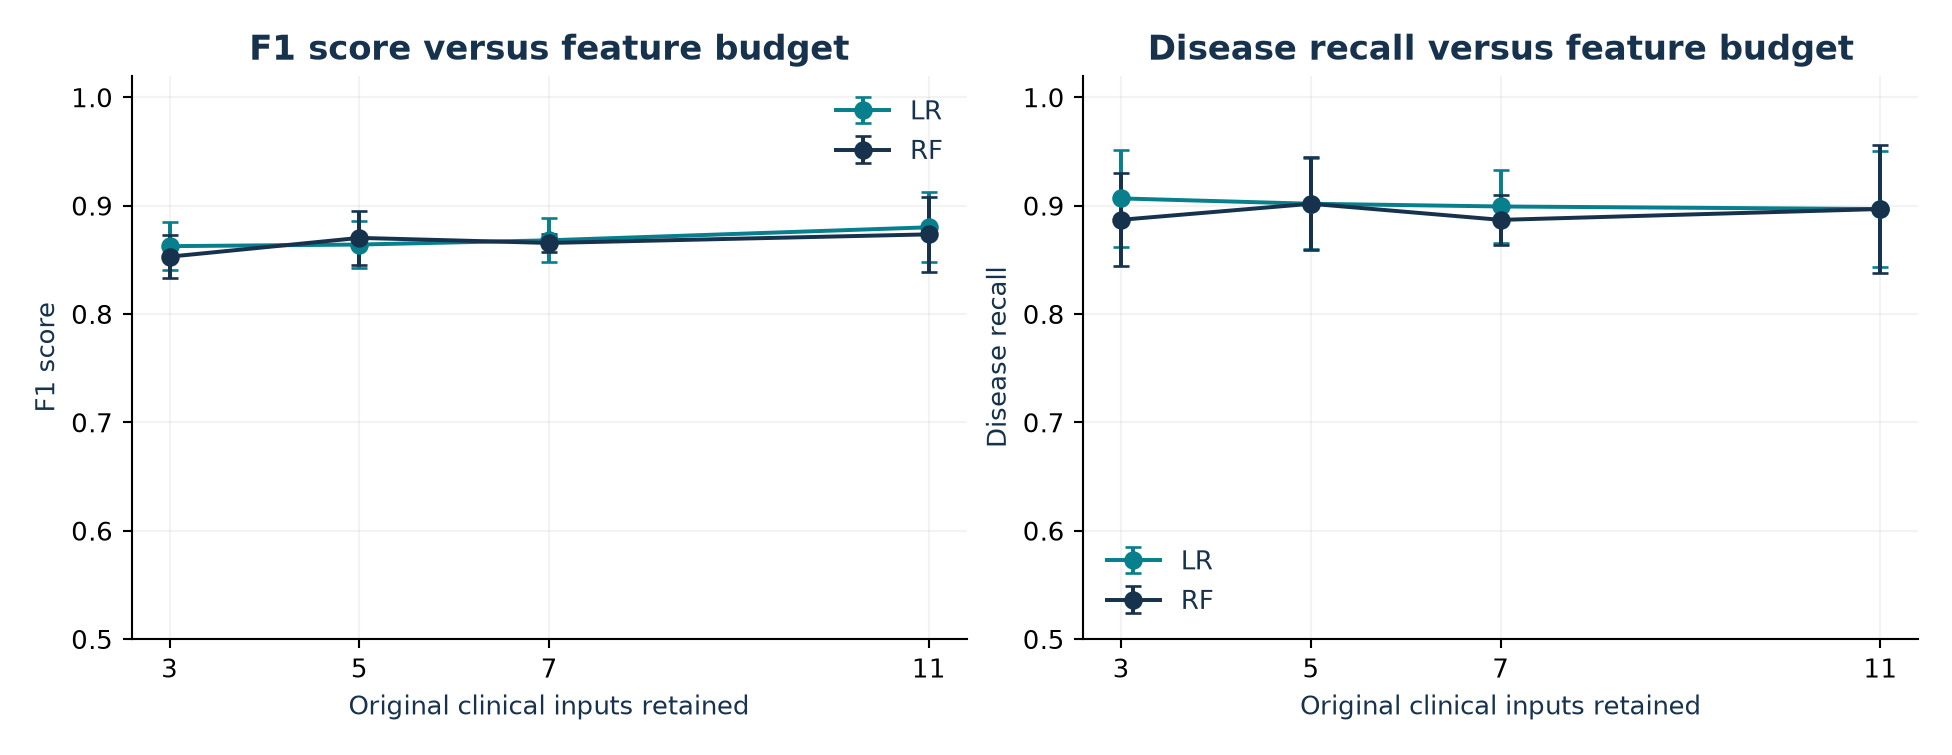

Three-input LR accuracy: **84.06%**; all-11 LR accuracy: **86.51%**. Removing inputs has a measured trade-off; report recall and specificity too.

In [8]:
summary = pd.read_csv(OUT / 'tables/summary.csv')
adaptive = pd.read_csv(OUT / 'tables/adaptive_compact_summary.csv')
display(summary.round(4))
display(adaptive.round(4))
display(Image(filename=str(OUT / 'figures/01_performance.png'), width=1000))
lr = summary.loc[summary.family.eq('LR')].set_index('budget')
display(Markdown(
    f"Three-input LR accuracy: **{lr.loc[3, 'accuracy_mean']:.2%}**; "
    f"all-11 LR accuracy: **{lr.loc[11, 'accuracy_mean']:.2%}**. "
    "Removing inputs has a measured trade-off; report recall and specificity too."))

## 5. Which variables are selected consistently?

Frequency counts how many of five outer training partitions select a variable.
Mean pairwise Jaccard is intersection divided by union across selected subsets; 1 means
identical subsets. It is a descriptive stability measure, not causal importance or proof
that an omitted variable is medically unnecessary.

,fold,budget,features,inner_f1,chosen_compact
0,0,3,"[""ST_Slope"", ""Cholesterol"", ""Sex""]",0.862428,False
1,0,5,"[""ST_Slope"", ""Cholesterol"", ""Sex"", ""FastingBS""...",0.863476,True
2,0,7,"[""ST_Slope"", ""Cholesterol"", ""Sex"", ""FastingBS""...",0.865348,False
3,0,11,"[""Age"", ""Sex"", ""ChestPainType"", ""RestingBP"", ""...",0.872838,False
4,1,3,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak""]",0.862756,True
5,1,5,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak"", ""Fastin...",0.865693,False
6,1,7,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak"", ""Fastin...",0.876814,False
7,1,11,"[""Age"", ""Sex"", ""ChestPainType"", ""RestingBP"", ""...",0.869005,False
8,2,3,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak""]",0.861171,True
9,2,5,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak"", ""Sex"", ...",0.875239,False


,budget,mean_pairwise_jaccard,folds
0,3,0.650000,5
1,5,0.500000,5
2,7,0.543889,5


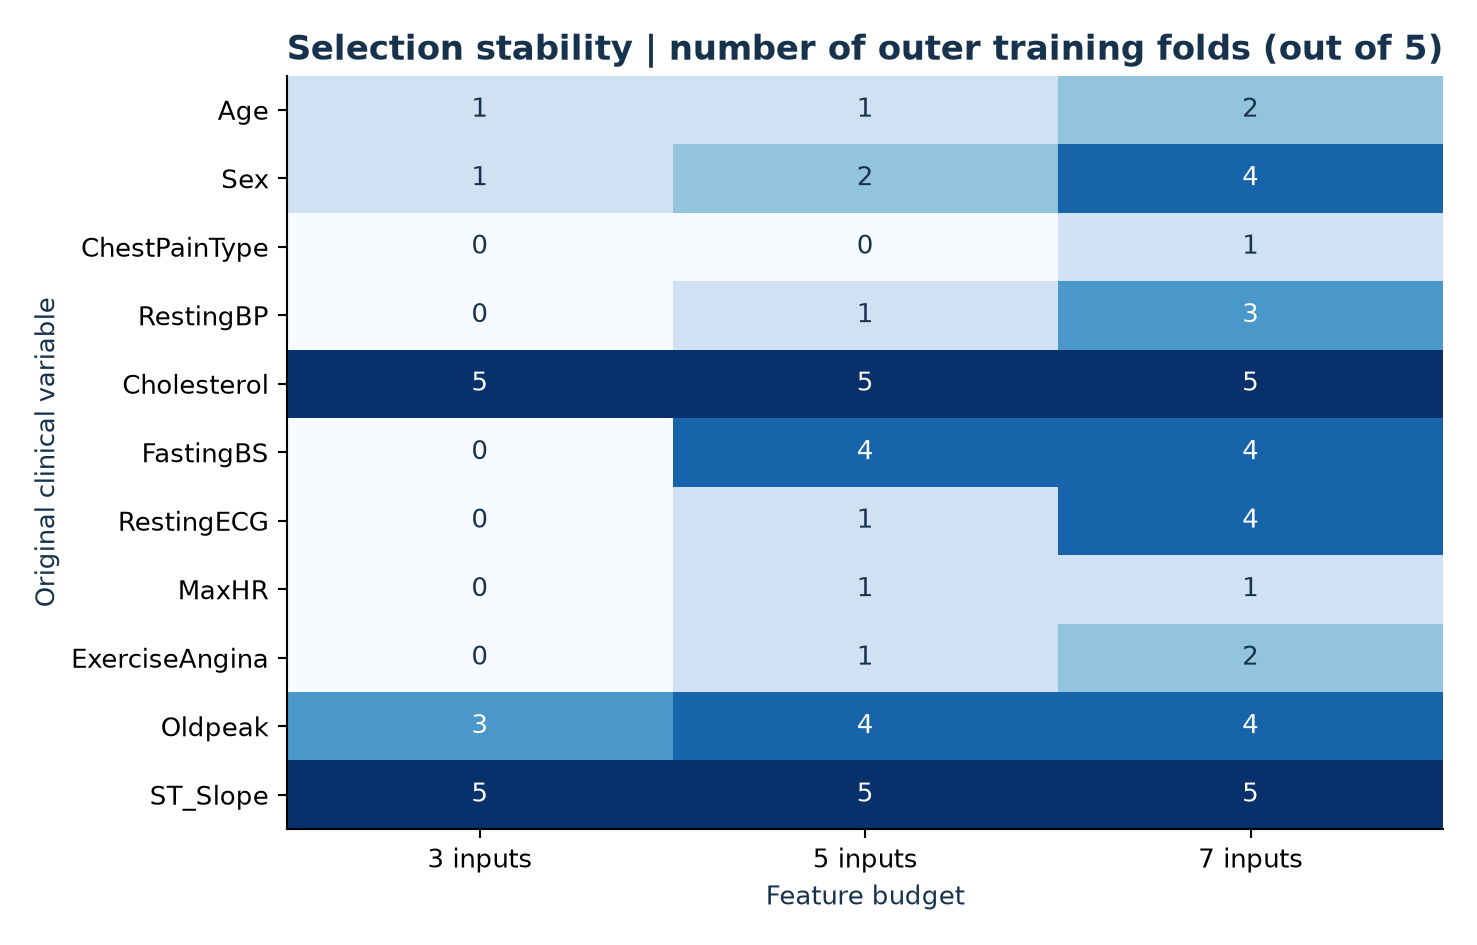

Compact choices made inside outer training partitions:


,fold,budget,features,inner_f1
1,0,5,"[""ST_Slope"", ""Cholesterol"", ""Sex"", ""FastingBS""...",0.863476
4,1,3,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak""]",0.862756
8,2,3,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak""]",0.861171
12,3,3,"[""ST_Slope"", ""Cholesterol"", ""Oldpeak""]",0.873382
16,4,3,"[""ST_Slope"", ""Cholesterol"", ""Age""]",0.865468


In [9]:
subsets = pd.read_csv(OUT / 'tables/selected_subsets.csv')
display(subsets)
display(pd.read_csv(OUT / 'tables/stability.csv'))
display(Image(filename=str(OUT / 'figures/02_stability.png'), width=850))
print('Compact choices made inside outer training partitions:')
display(subsets.loc[subsets.chosen_compact, ['fold', 'budget', 'features', 'inner_f1']])

## 6. Final compact model for demonstration

The final subset comes from applying the same procedure to all development records.
It has no fresh independent performance test. Its inner score is not a final accuracy
estimate. The outer scores above assess the workflow rather than this exact final subset.

In [10]:
bundle = joblib.load(OUT / 'models/compact_model.joblib')
display(Markdown(f"Final demonstration subset: **{bundle['budget']} inputs**: "
                 + ', '.join(bundle['features'])))
examples = data.loc[bundle['train_ids'][:3], bundle['features']]
display(examples)
print('Illustrative development-row predictions:', bundle['model'].predict(examples))
print('These examples are not test evidence.')

Final demonstration subset: **3 inputs**: ST_Slope, Cholesterol, RestingECG

,ST_Slope,Cholesterol,RestingECG
0,Up,289,Normal
3,Flat,214,Normal
4,Up,195,Normal


Illustrative development-row predictions: [0 1 0]
These examples are not test evidence.


## 7. Findings, limitations, and improvements

- The three-input LR procedure loses mean accuracy relative to all 11 inputs. Smaller
  models are not automatically better; disease recall and specificity must also be checked.
- ST slope and cholesterol appear in all five three-input outer-training subsets. The
  third input varies. RestingECG appears in the final development subset, so the exact final
  three inputs are not a universally confirmed ranking.
- Cholesterol selection also retains its missingness indicator. Collection practices
  may partly explain its usefulness. Test this with a predeclared missingness ablation.
- Fewer variables do not necessarily mean cheaper collection: ECG and exercise-test
  summaries can still require diagnostic measurements. No acquisition costs were measured.
- Greedy selection is an established method and can miss interactions. A future study
  could compare other selectors and repeat nested evaluation with additional seeds.
- Source collections overlap the paper's dataset. Independent compatible data would be
  needed for external validation. These models are academic demonstrations.

The contribution is a measured feature-reduction study with stability analysis, beyond
changing the classifier or reading a single feature-importance ranking.

Candidate scores, subset choices, fold membership, predictions, complete metrics, and
figures are saved in `output/feature_selection/`. Fitted models are regenerated locally.
The original holdout remains excluded from this extension.

## References

- [Original CART paper](https://doi.org/10.1016/j.health.2022.100130).
- [Dataset source](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction).
- [scikit-learn feature selection](https://scikit-learn.org/stable/modules/feature_selection.html).
- [Nested evaluation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

AI assisted preparation; numerical results are generated by execution.